# Road Accident Predictions with Graph Neural Networks

## Introduction

Road traffic accidents impose substantial human and economic costs, estimated to cost an average of 2.7% of GDP in high-income countries (Wijnen & Stipdonk, 2016). They can be caused by pedestrians, drivers, vehicles, or the road environments. Although human behaviour is an important factor in crashes, road environments may also contribute by influencing the likelihood of driver errors and violations (Ahmad et al., 2021). Differences in road layout, traffic volume, surrounding land use and environmental conditions can contribute to differences in where crashes occur. Understanding the relationship between road characteristics and accidents may therefore help transport agencies identify road segments with elevated accident risk and prioritise them for safety assessment and improvements.

Machine learning offers a way to combine information about roads and their surroundings to predict where accidents are more likely to occur. Relevant information may include historical accident records, traffic volume and road characteristics. However, roads do not exist in isolation: connected road segments may share traffic flows, infrastructure and environmental conditions. This suggests that the relationships between roads may provide useful information for accident prediction. Graph-based methods provide a way to account for these connections when predicting accidents.

### Objectives

This project uses the ML4RoadSafety benchmark to study monthly accident prediction on road networks (Nippani et al., 2023). It aims to assess how well models predict monthly accidents on physical roads and whether additional information like network structure, additional road context, and previous accident records can improve those predictions.

### Research questions
> [!NOTE]
> Need to rewrite once the report is confirmed

1. **Network representation and learning:** How does the use of different graph machine learning methods improve the prediction of road traffic accident predictions?
2. **Road features and history**: To what extent do richer road characteristics and historical accident information improve monthly road-level accident prediction?

### Main contributions
> [!NOTE]
> Need to rewrite once the report is confirmed

- We compare an MLP and edge-aware GraphSAGE, with and without Node2Vec, under a shared physical-road target and chronological evaluation protocol.
- We develop an OSM enrichment and matching pipeline, audit its coverage, and assess its predictive value and feature reliance for GraphSAGE classification.
- We construct a past-only accident history representation and examine training-period evidence of temporal persistence, complemented by interactive spatial exploration.

These experiments adapt the benchmark's features, embeddings and target aggregation, so the reported scores constitute a modified reproduction rather than direct replications of the published results.


## Related Work

### Road Accidents Predictions

Existing work have explored the use of various methods to predict road accidents, ranging from statistical models, machine learning models, and deep learning models. Statistical learning approaches relate expected accident counts to road and traffic characteristics using count regression. Ma et al. (2017) applied negative-binomial and random-effects negative-binomial models to predict crash frequency on segments of a Chinese expressway using explanatory variables such as road geometry, and also explored the spatial and temporal correlation in the accidents data.

Traditional machine-learning approaches use algorithms like random forest and support vector machines to predict crashes (Guerra et al., 2022). Guerra et al. compared linear regression, Generalised Additve models, random forest, support vector machines, and artificial neural network on the traffic prediction task. They found that random forests produced the best results and the traffic volume given by annual average daily traffic (AADT), was a significant variable in predicting the crashes.

Deep-learning approaches can learn richer representations from information about roads to predict traffic accidents. Kashifi et al. (2023) developed a hybrid model combining convolutional neural networks, LSTMs and artificial neural networks for short-term crash prediction. They used information such as average speed, vehicle occupancy, weather data, temporal information, and crash data from the Paris road network, combining multiple different information to predict road traffic accidents.

Graph-based approaches are well suited for road accident prediction because roads form an interconnected network, and conditions on one road may be related to those on neighbouring roads. Graph models can represent these relationships explicitly and aggregate information between related road segments to improve predictions. Huang and Hooi (2022) developed TRAVEL, a graph neural network that incorporates road geometry and connectivity to predict accident occurrence and severity at intersections. Their model achieved better overall F1 and AUC scores than non-graph XGBoost and MLP baselines on their city datasets. Furthermore, their experiments also used other graph neural network (GNN) models such as Graph Convolutional Network (GCN) (Kipf & Welling, 2016), GraphSAGE (Hamilton et al., 2017), and ChebNet (Defferrard et al., 2016), which achieved better scores compared to the non-graph methods, supporting the argument that graph methods are well suited for road accident prediction tasks.

### Graph representation learning

Graph representation learning provides a framework for incorporating road-network structure into accident prediction. A road network can be represented as a graph whose nodes denote intersections and whose edges denote road segments. This representation allows a model to combine the attributes of a location with information from its connected roads and neighbouring intersections. Several methods differ in how they encode this structure and determine the contribution of neighbouring locations.

Node2Vec is a form of shallow graph learning that learns a vector representation for each node in the graph, which can be used for downstream predictive tasks (Grover & Leskovec, 2016). It is adapted from word2vec (Mikolov et al., 2013), where words are represented by nodes, while sentences are represented by biased random walk sequences along the graph. The biased random walk is obtained through a sampling process, controlled by two parameters, $p$ and $q$, which controls the probability of moving back to the previous node, and controls the probability of local or outward exploration. This provides more flexibility to the representation it can capture. Furthermore, it uses a skip-gram objective function, which helps to encourage nodes that are in the same random walk, and therefore likely to be close to one another, to have similar embeddings.

GraphSAGE learns node representations by performing uniform sampling around the node's neighbourhood, followed by aggregating features of the sampled nodes (Hamilton et al., 2017). Some examples of aggregation include using the mean, maximum, or using a Long Short Term Memory (LSTM) (Hochreiter & Schmidhuber, 1997). A non-linear transformation is applied to the concatenation of the node's features and its sampled neighbourhood, through multiple layers of aggregation. The multiple layers of aggregation helps to incorporate information from increasingly distant neighbours, allowing a node to capture more context and information beyond its neighbourhood.

However, GraphSAGE is an isotropic GNN. This means that the neighbours have no canonical direction labels and the different edges all same the same magnitude and weight regardless of their importance. GatedGCN (Bresson & Laurent, 2017) and Graph Transformers (Dwivedi & Bresson, 2020) are anisotropic GNNs which allow the contribution of neighbouring nodes to vary. GatedGCN uses learnable edge gates to control the contribution of neighbouring nodes during aggregation. The gates are learned from node and edge representations, allowing the model to adjust messages according to the relationship between connected nodes. Since the edge representations will get updated, GatedGCN can perform edge-aware message passing, which helps to improve tasks requiring edge predictions.

Graph Transformers (Dwivedi & Bresson, 2020) extend Transformers (Vaswani et al., 2017) to the graph domain by using the attention mechanism to assign weights to neighbouring nodes, restricting how nodes access and share information with one another. The attention mechanism assigns weights to these neighbours based on their representations, allowing their contributions to vary during aggregation. It also incorporates edge features into the attention mechanism, allowing attributes of the connections between nodes to influence the learned representations. In addition, Laplacian eigenvectors are used as node positional encoding to inject structural information to increase the expressivity of the models.

## Dataset and Exploratory Analysis

### ML4RoadSafety dataset

ML4RoadSafety is a public road-safety dataset constructed from official accident reports across eight US states, comprising more than nine million records in the full collection (Nippani et al., 2023). It links accident locations and dates to road networks derived from OpenStreetMap (OSM). Each state is represented as a directed graph, where nodes correspond to intersections and edges represent road segments. The dataset includes node-level structural and weather information, such as node degrees, coordinates, temperature and precipitation, as well as edge-level attributes, including road length, road category and AADT, where available. Accident records are associated with road-network edges and can be used to study monthly accident counts and occurrence. The dataset is available through [Harvard Dataverse](https://doi.org/10.7910/DVN/V71K5R). 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
# Use Google Drive in Colab, or the local repository otherwise.
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/gdrive')
    PROJECT_DIR = Path(os.environ.get(
        'CS5284_PROJECT_DIR', '/content/gdrive/MyDrive/cs5284_project'))
else:
    configured = os.environ.get('CS5284_PROJECT_DIR')
    if configured:
        PROJECT_DIR = Path(configured).expanduser()
    else:
        PROJECT_DIR = next(
            (p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'src' / 'eda.py').is_file()), None)
        if PROJECT_DIR is None:
            raise FileNotFoundError('Open this notebook inside the repository or set CS5284_PROJECT_DIR.')

PROJECT_DIR = PROJECT_DIR.resolve()
if not (PROJECT_DIR / 'src' / 'eda.py').is_file():
    raise FileNotFoundError(f'Place the repository (including src/eda.py) in {PROJECT_DIR}, or update PROJECT_DIR.')
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
DATA_DIR = Path(os.environ.get('CS5284_DATA_DIR', str(PROJECT_DIR / 'data'))).expanduser().resolve()
os.environ['CS5284_PROJECT_DIR'] = str(PROJECT_DIR)
os.environ['CS5284_DATA_DIR'] = str(DATA_DIR)
print(f'Project: {PROJECT_DIR}')
print(f'Data: {DATA_DIR}')


Project: C:\Users\aaron\OneDrive\Desktop\NUS\Masters of Computing (AI Specialisation)\Sem 4\CS5284\Project\CS5284_GML
Data: C:\Users\aaron\OneDrive\Desktop\NUS\Masters of Computing (AI Specialisation)\Sem 4\CS5284\Project\CS5284_GML\data


In [3]:
from IPython.display import display
import matplotlib.pyplot as plt
from src.reporting import apply_report_style
apply_report_style()
from src.eda import (
    load_data, dataset_summary, split_summary, audit_data,
    accident_distribution, concentration, historical_persistence,
    plot_monthly_accidents, plot_risk_profile,
)

STATES = ('DE',)
data = load_data(DATA_DIR, states=STATES)
summary = dataset_summary(data)
audit = audit_data(data)
distribution = accident_distribution(data)
concentration_table = concentration(data)

This study focuses on the state of Delaware, covering the period spanning January 2009 to September 2022. Descriptive statistics found some discrepancies between the dataset that we used and the ones reported in the original paper. The differences were likely due to rounding errors or minor enough to ignore. In general, we observed that Delware has 49,023 nodes and 116,196 edges, with an average monthly accidents of 2,777 accidents per month. Data quality audit was also performed to check for missing, duplicated, or abnormal data on accident records and node information. There were no invalid accident counts or duplicated entries. However, some weather and traffic data were missing. The comparison between some statistics reported in the paper and what we found in the data is summarised in the table below. 


In [4]:
import pandas as pd

# The published values below are transcribed from Nippani et al. (2023), Table 1.
metrics = [
    ('Period', 'Period', '2009–2022', 'text'),
    ('Nodes', 'Nodes', '49,023', 'int'),
    ('Directed road segments', 'Directed edges', '116,196', 'int'),
    ('Average accidents per month', 'Accidents/month', '2,763', 'int'),
    ('Average outgoing degree', 'Mean degree', '2.4', 'decimal'),
    ('Maximum outgoing degree', 'Max degree', '6', 'int'),
    ('Average directed segment length (m)', 'Mean length (m)', '213', 'int'),
    ('Traffic coverage: physical-road proxies (%, any year)', 'Traffic coverage (%)', '3.14%', 'percent'),
]

def format_value(value, kind):
    if kind == 'text':
        return str(value)
    if kind == 'int':
        return f'{value:,.0f}'
    if kind == 'decimal':
        return f'{value:.1f}'
    return f'{value:.2f}%'

rows = []
for label, key, paper_de, kind in metrics:
    row = {'Measure': label}
    for state, paper in [('Delaware', paper_de)]:
        if state in summary.index:
            row[f'{state}: this analysis'] = format_value(summary.loc[state, key], kind)
            row[f'{state}: paper'] = paper
    rows.append(row)
comparison = pd.DataFrame(rows).set_index('Measure')
display(comparison)

,Delaware: this analysis,Delaware: paper
Measure,,
Period,2009-01 to 2022-09,2009–2022
Nodes,"49,023","49,023"
Directed road segments,"116,196","116,196"
Average accidents per month,"2,777","2,763"
Average outgoing degree,2.4,2.4
Maximum outgoing degree,6,6
Average directed segment length (m),213,213
"Traffic coverage: physical-road proxies (%, any year)",3.16%,3.14%


### Graph Laplacian analysis

We analyse the road network using the symmetric normalized Laplacian, $L_{\mathrm{sym}} = I-D^{-1/2}AD^{-1/2}$. A connection in either direction is treated as an undirected, unweighted edge; reciprocal and duplicate edges are collapsed and self-loops removed. The graph contains 75 connected components, including 18 isolated intersections. The largest component contains 48,727 of 49,023 intersections, or approximately 99.40% of all roads. We focus the spectral analysis on this component to examine connectivity within the main road network.

Its second-smallest normalized Laplacian eigenvalue is approximately $2.37 \times 10^{-6}$, suggesting a loosely connected partition within the main network. The map shows the corresponding eigenvector where it shows a gradual pattern from north to south. This suggests that the road network’s connectivity varies across Delaware: intersections in the north tend to have similar eigenvector values, as do those in the south, with central Delaware forming a gradual transition between them. This might be explained by the expressways connecting the north and south parts of Delaware.

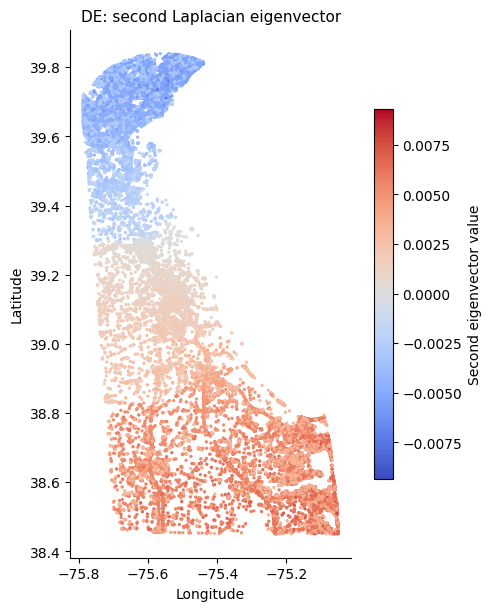

In [14]:
from src.eda import graph_laplacian_eda

laplacian_summary, laplacian_figures = graph_laplacian_eda(data)
display(laplacian_figures[0])
plt.close(laplacian_figures[0])

### Exploratory Data Analysis

### Recorded accidents over time

The figure below shows a time series plot of the recorded accidents over time for Delaware. The plots segment the periods according to the training, validation, and test sets used in the original paper from Nippani et al. (2003). As Delaware's data starts from an earlier date, the recorded accidents begun much earlier in 2009. We observed a significant increasing trend for the number of accidents at the start for Delaware, followed by the a much slower increase over time. However, it experienced a significant drop in accidents around April 2020. This coincides with the lockdown orders placed during the COVID-19 pandemic (Castillo et al., 2020). The accidents slowly recovered to their previous values after the lockdown period.

Furthermore, we also analysed the potential of any seasonality in the data. We observed that there is a consistent seasonality in both states where the mean recorded accidents are lower at the start of the year and slowly increase from January to December. The last quarter of the year usually has a higher mean recorded accidents. This might be attributed to increased travelling due to the upcoming festive season of Thanksgiving, Christmas, and New Year.

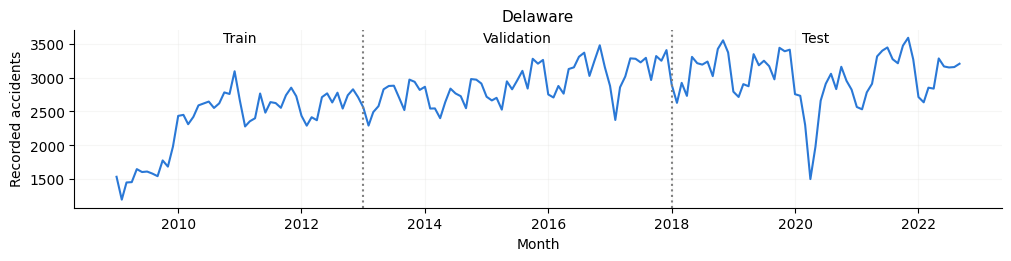

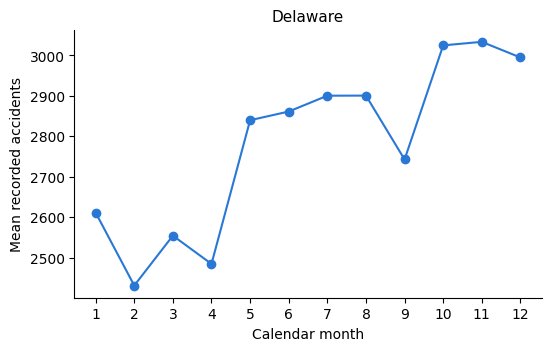

In [15]:
from src.eda import plot_seasonality

fig = plot_monthly_accidents(data)
plt.show()

fig = plot_seasonality(data)
plt.show()


To compare the effect of accident lags across time, we calculated the proportion of road-months that recorded at least one accident, grouped according to whether the same road had recorded an accident during a preceding time window. A road-month refers to one road segment observed during one calendar month. For example, the previous-month probability is the number of road-months with accidents in both the current and previous month divided by the number with an accident in the previous month. We looked at time lags of one, three, six, and twelve months.


Using training-period data, roads with a previous-month accident recorded another accident in 21.81% of subsequent months in Delaware. For roads without an accident in the previous month, the corresponding proportions were 2.44%. The pattern is consistent for other time lags for three, six, and twelve months for both states, but with lower probabilities for longer lags. This suggests that an accident happening in a road may indicate a higher probability of an accident on the same road in the future, which further suggests that accident history may be a suitable feature to include in road accidents predictions.

In [16]:
from src.eda import history_window_risk
history_windows = history_window_risk(data)
display(history_windows.style.format({'Road-months': '{:,.0f}', 'Accident road-months': '{:,.0f}',
                                     'Next-month accident (%)': '{:.2f}'}))


,State,Prior months,History,Road-months,Accident road-months,Next-month accident (%)
0,Delaware,1,None,"2,975,238","72,470",2.44
1,Delaware,1,One or more,"91,606","19,981",21.81
2,Delaware,3,None,"2,721,525","51,794",1.90
3,Delaware,3,One or more,"214,815","38,333",17.84
4,Delaware,6,None,"2,411,285","36,357",1.51
5,Delaware,6,One or more,"329,299","49,749",15.11
6,Delaware,12,None,"1,911,333","21,990",1.15
7,Delaware,12,One or more,"437,739","55,553",12.69


### Accident sparsity and concentration

Accident counts are sparse at the road-month level. In Delaware, 96.52% of roads recorded no accidents in a given month. Positive counts are therefore concentrated in a small proportion of road-months. Accidents are also unevenly distributed across roads. Over the full observation period, the 10% of roads with the highest recorded counts accounted for 70.6% of accidents in Delaware. These patterns indicate that accidents are highly sparse and concentrated in a small proportion of roads, and may suggests that prediction tasks should be able to account for the imbalance and use suitable metrics.

,Road-months,Zero accidents (%),Mean count
State,,,
Delaware,"10,766,580",96.52,0.0426


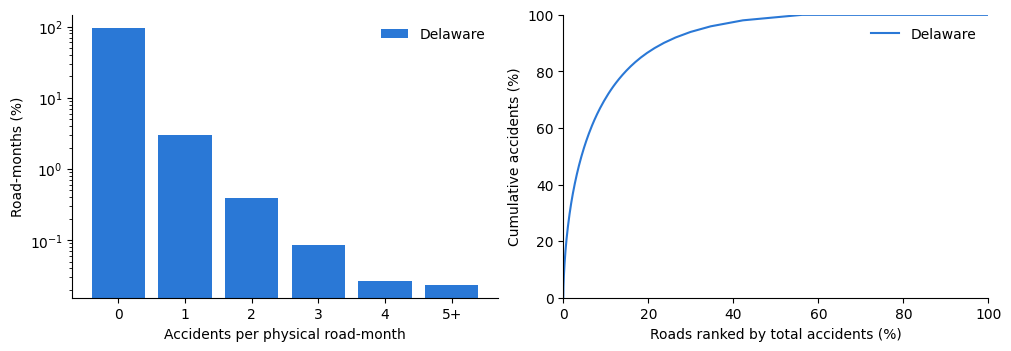

In [17]:
display(distribution[['Road-months', 'Zero accidents (%)', 'Mean count']].style.format({
    'Road-months': '{:,.0f}', 'Zero accidents (%)': '{:.2f}', 'Mean count': '{:.4f}',
}))
fig = plot_risk_profile(data)
plt.show()


### Road characteristics, traffic volume, and accidents

We also analyse the relationship of road length, road type, and AADT against accidents per road-month, using data from the training period. For the analysis for road length amd AADT, the roads were first grouped into five quantiles based on their respective categories before plotting the graphs for better visibility, while the correlation was calculated using raw scores. In both states, road length was positively associated with an increase in mean road accidents, as given by the positive Spearman correlation of 0.224. For road type, motorways were the category with the strongest associated with the a higher mean accident per road-month in both states, while unclassified and residential roads have the weakest association. Only roads with a single road type and road types with at least 100 roads were included here. Lastly, for AADT, both states observed a positive correlation between AADT and mean accidents per road-month, with a Spearman correlation of 0.103. Together, these analyses showed that the road length, road type, and AADT may be useful features for predicting road accidents.

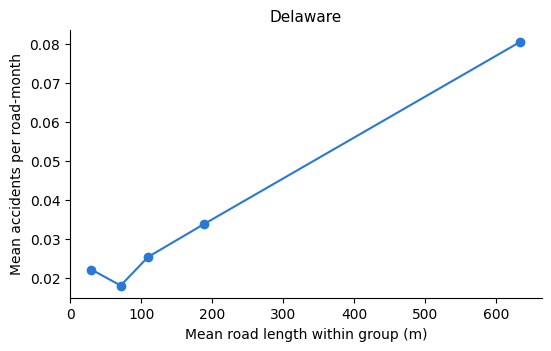

,Roads,Spearman correlation
State,,
Delaware,"65,252",0.224


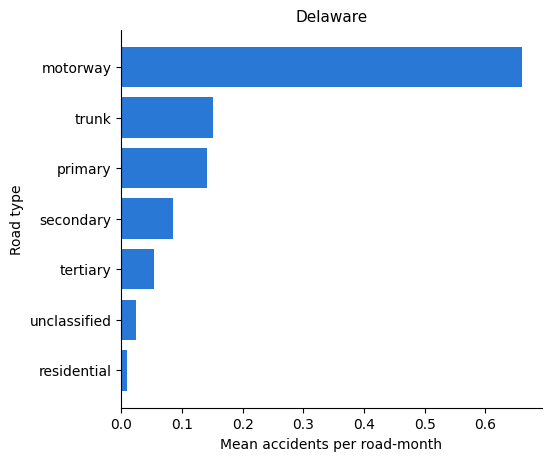

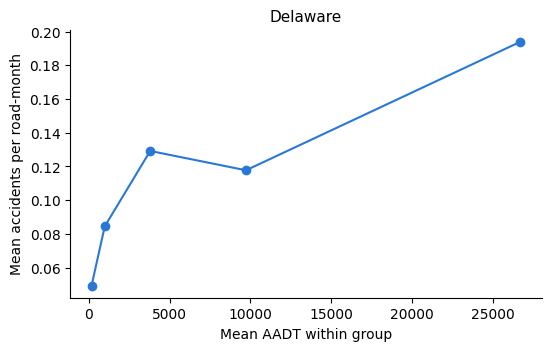

,Observed road-years,Spearman correlation
State,,
Delaware,"2,691",0.103


In [18]:
import numpy as np
import pandas as pd
from src.eda import (plot_length_risk, plot_road_type_risk, traffic_accident_association,
                     plot_traffic_risk, _feature_series, _risk, STATE_NAMES)

# Figure 4: road length and training-period accident counts.
fig = plot_length_risk(data)
plt.show()
length_stats = []
for state, state_data in data.items():
    lengths = _feature_series(state_data.edge_features['length'], state_data.n_nodes, physical=True)
    pairs = pd.DataFrame({'Length (m)': lengths.reindex(state_data.roads),
                          'Mean monthly accidents': _risk(state_data)}).dropna()
    pairs = pairs[pairs['Length (m)'] > 0]
    length_stats.append({'State': STATE_NAMES[state], 'Roads': len(pairs),
                         'Spearman correlation': pairs.corr(method='spearman').iloc[0, 1]})
display(pd.DataFrame(length_stats).set_index('State').style.format(
    {'Roads': '{:,.0f}', 'Spearman correlation': '{:.3f}'}))

# Figure 5: recorded road type and training-period accident counts.
fig = plot_road_type_risk(data)
plt.show()

# Figure 6: observed annual AADT and accident counts from the same year.
traffic_observations = traffic_accident_association(data)
fig, traffic_stats = plot_traffic_risk(traffic_observations)
plt.show()
display(traffic_stats.style.format({'Observed road-years': '{:,.0f}', 'Spearman correlation': '{:.3f}'}))


### Spatial exploration of recorded accidents

We also inspect the spatial distribution of road accidents visually through an interactive map below. In Delaware, accidents are concentrated in the northern part of the state, particularly around Wilmington. Linear patterns extend southward towards central and southern Delaware, including the area around Dover. These patterns may correspond to major expressways connecting to different parts of the state. This north–south pattern also resembles the gradual change in eigenvector values observed in the graph Laplacian analysis, which reflects the connectivity of the road network. The interactive map will also show the predicted model results from the later sections.

In [19]:
from src.visualization.risk_map import show_risk_map
from IPython.display import FileLink, display

SHOW_INTERACTIVE_MAPS = True
MAP_MAX_ROADS = None  # Display every road in each state network.
MAP_OUTPUT_DIR = PROJECT_DIR / 'results' / 'visualizations'
if SHOW_INTERACTIVE_MAPS:
    eda_map_path = show_risk_map(
        PROJECT_DIR, max_roads=MAP_MAX_ROADS, mode='eda',
        data_dir=DATA_DIR, results_dir=PROJECT_DIR / 'results', state_codes=STATES,
        output_path=MAP_OUTPUT_DIR / 'road_safety_full_eda.html',
    )
    display(FileLink(str(eda_map_path), result_html_prefix="Open standalone map: "))


Saved standalone application: C:\Users\aaron\OneDrive\Desktop\NUS\Masters of Computing (AI Specialisation)\Sem 4\CS5284\Project\CS5284_GML\results\visualizations\road_safety_full_eda.html


C:\Users\aaron\OneDrive\Desktop\NUS\Masters of Computing (AI Specialisation)\Sem 4\CS5284\Project\CS5284_GML\results\visualizations\road_safety_full_eda.html

## Methodology

### Prediction tasks and target construction

For prediction, this study groups directed edges with the same unordered endpoints into a single **physical-road proxy**, summing their accident counts for each month. The original benchmark instead defines its prediction task at the directed-edge level (Nippani et al., 2023). Our message-passing graph remains directed. A **road-month** is one physical-road proxy observed in one month: classification predicts whether its count exceeds zero, while regression estimates the count. Zero-count roads are included in the target population. Endpoint-based grouping does not establish that every grouped pair is the same physical road and does not support direction-specific conclusions.

Our feature construction, structural embedding implementation, physical-road aggregation and evaluation population adapt the original benchmark. These methodological changes make the experiments a modified reproduction, so their scores are not direct replications of the published benchmark results.

### Baseline models and road-level prediction

We compare an MLP with the benchmark's edge-aware GraphSAGE adaptation (Hamilton et al., 2017; Nippani et al., 2023), each with and without fixed Node2Vec embeddings (Grover & Leskovec, 2016). GraphSAGE produces intersection representations through message passing; the MLP omits this graph encoder. A shared road-level predictor combines endpoint representations with road attributes. Monthly inputs include weather and available traffic; structural inputs include coordinates, degree and approximate betweenness. Classification and regression use separate task-specific models.


### Past-only accident-history representation

The history representation comprises six own-road features: last-month count, 3/6/12-month means, twelve-month lag and twelve-month nonzero fraction. Three neighbourhood features describe last-month and three-month mean counts on adjacent roads and the number of neighbours. A coverage indicator records the number of usable prior months. Every dynamic input for target month T ends at T−1. Incomplete windows remain missing, and absent source months are not automatically treated as accident-free.

Opposite-direction counts are summed **before** history construction, and the resulting physical-road features are broadcast to both message-passing directions. Neighbours are distinct physical connections sharing an endpoint, excluding the target road and its reverse. This aligns historical inputs with the prediction target and prevents the unused label direction from being treated as an independent accident-free road.

The descriptive history analysis uses a twelve-month warm-up and is restricted to **2010–2012 Delaware training targets**, leaving 36 eligible months. This past-only cutoff follows the temporal evaluation principle described by Hyndman and Athanasopoulos (2021, Section 5.10). The analysis examines associations with subsequent counts; it does not estimate the incremental performance of a history-enhanced predictive model.


## Experimental Setup

### Training and model selection

Baseline experiments cross **MLP/GraphSAGE × classification/regression × Node2Vec off/on**, giving eight Delaware configurations. Each uses three model seeds (0, 1 and 2), 100 epochs, two width-256 layers, zero dropout and Adam at learning rate 0.001 (Kingma & Ba, 2015). Training samples positive and zero-count roads at a 1:1 ratio; validation and testing include all physical roads. Classification minimises binary cross-entropy. Regression minimises MAE, with negative count predictions clipped to zero at evaluation.

Validation is performed every five epochs and at the final epoch. The checkpoint with highest validation AUROC for classification or lowest validation MAE for regression is evaluated on test. This is checkpoint selection, without early termination of training. Chronological splits are shown in Table 2.

### Evaluation metrics

Primary AUROC is calculated monthly and averaged using positive-road counts as weights. **AP** denotes scikit-learn average precision, rather than trapezoidal area under the precision-recall curve (scikit-learn developers, n.d.). Top-1% precision and recall assess prioritisation. Subgroup AUROC is pooled across road-months and distinguished from the primary monthly metric. Reported spreads are population standard deviations (`ddof=0`) across the three model seeds, rather than confidence intervals.


## Results and Discussion

### Baseline comparisons

Tables 6–7 compare the eight Delaware configurations across three seeds. Classification is assessed primarily by AUROC and count regression by MAE. Each configuration is reported separately; test performance is not used to select among repeated runs.


In [13]:
from src.reporting import load_training_results, format_training_results, plot_training_history

RESULTS_DIR = PROJECT_DIR / 'results'
training_results = load_training_results(RESULTS_DIR)
if training_results.empty:
    print('No completed ordinary training results are available in', RESULTS_DIR)
else:
    display(format_training_results(training_results, 'classification').style.hide(axis='index').set_caption(
        'Table 6. Classification performance: mean ± SD across model seeds. AP is average precision.'))
    display(format_training_results(training_results, 'regression').style.hide(axis='index').set_caption(
        'Table 7. Count-regression performance: MAE is primary; AUROC evaluates ranking by predicted counts.'))
    # Provenance remains available for inspection alongside each run.
    training_provenance = training_results[['Run', 'Source commit', 'Dirty checkout']]


State,Model,Node2Vec,Seeds,AUROC,AP,Run
DE,graphsage,With,3,0.8743 ± 0.0003,0.2627 ± 0.0013,DE_graphsage_classification_n2v
DE,graphsage,Without,3,0.8461 ± 0.0037,0.2134 ± 0.0024,DE_graphsage_classification_no_n2v
DE,mlp,With,3,0.8780 ± 0.0002,0.2788 ± 0.0016,DE_mlp_classification_n2v
DE,mlp,Without,3,0.8449 ± 0.0008,0.2112 ± 0.0013,DE_mlp_classification_no_n2v


State,Model,Node2Vec,Seeds,MAE,AUROC,Run
DE,graphsage,With,3,0.2070 ± 0.0038,0.8569 ± 0.0025,DE_graphsage_regression_n2v
DE,graphsage,Without,3,0.2316 ± 0.0048,0.8357 ± 0.0013,DE_graphsage_regression_no_n2v
DE,mlp,With,3,0.2201 ± 0.0040,0.8648 ± 0.0011,DE_mlp_regression_n2v
DE,mlp,Without,3,0.2506 ± 0.0022,0.8161 ± 0.0028,DE_mlp_regression_no_n2v


Node2Vec improves both baseline architectures in the Delaware experiments. With Node2Vec, the MLP achieves higher classification AUROC (**0.8780**) than GraphSAGE (**0.8743**), while GraphSAGE achieves lower count-regression MAE (**0.2070**) than the MLP (**0.2201**). The benefit of learned message passing therefore depends on the prediction task. Structural embeddings remain useful even without a learned graph encoder, and the graph model is not uniformly stronger.


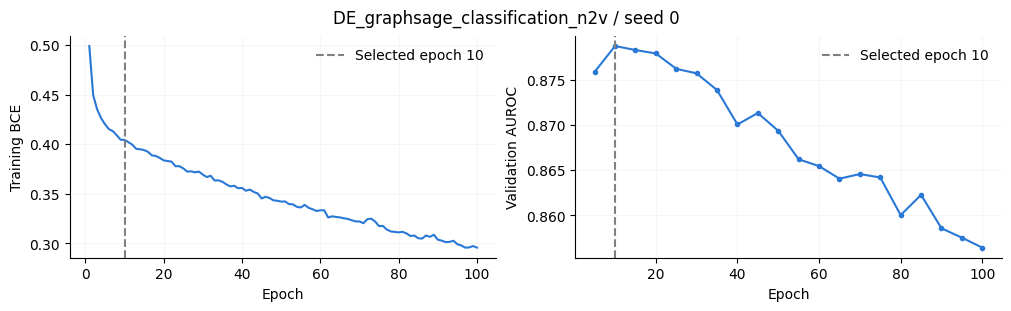

In [14]:
HISTORY_RUN = 'DE_graphsage_classification_n2v'
HISTORY_SEED = 0
if (RESULTS_DIR / HISTORY_RUN / f'seed{HISTORY_SEED}_history.csv').exists():
    fig = plot_training_history(RESULTS_DIR, HISTORY_RUN, HISTORY_SEED)
    plt.show()
else:
    print('Training history unavailable for', HISTORY_RUN)


*Figure 3. Training loss and validation AUROC for GraphSAGE with Node2Vec, seed 0.* The marked checkpoint is selected by validation performance. Training loss uses sampled roads, whereas validation covers all roads; their magnitudes are not directly comparable. Test performance is reserved for final evaluation.


### Historical persistence of accident incidence

Table 10 relates next-month accident incidence to strictly prior three-month accident totals on physical roads. It uses only **2010–2012 Delaware training targets** after the twelve-month warm-up. History construction is checked for target alignment and invariance to changes in target-month and future labels, ensuring that the displayed association does not depend on those labels entering the inputs.

The probability of a next-month accident increases from **2.04%** following zero accidents in the previous three months to **75.80%** following six or more. Mean next-month count increases from **0.0221** to **2.1551** across the same categories. This gradient demonstrates temporal persistence in the training population. It may reflect persistent exposure, road characteristics and other unobserved differences between roads, rather than a causal effect of previous accidents.


In [17]:
import json
from src.history.integration import PhysicalHistory, history_readiness, training_risk_by_history
from src.history.features import run_self_checks

history_data = PhysicalHistory.load(DATA_DIR / 'DE')
history_branch_manifest = json.loads((PROJECT_DIR / 'reports/history_branch_manifest.json').read_text())
history_source_match = (history_data.source_audit['source_sha256'] == history_branch_manifest['source_sha256'])
print('Local accident/graph files match branch exports:', history_source_match)
print('Past-only source self-checks:', run_self_checks())
history_coverage = history_readiness(history_data)  # 36/60/57 with the matched warm-up.
display(training_risk_by_history(history_data).style.format({
    'Road-months': '{:,.0f}', 'Next-month accident probability (%)': '{:.2f}',
    'Mean next-month count': '{:.4f}',
}).hide(axis='index').set_caption(
    'Table 10. Subsequent accident incidence by strictly prior three-month physical-road history (2010–2012 training targets).'))


Prior 3-month accidents,Road-months,Next-month accident probability (%),Mean next-month count
0,"2,163,898",2.04,0.0221
1,"136,650",12.52,0.1475
2,"30,091",24.98,0.3232
3–5,"15,776",42.23,0.6418
6+,"2,657",75.80,2.1551


The history analysis is exploratory: its outcome is an association with subsequent incidence, rather than a measured gain in held-out AUROC or MAE. A predictive comparison would need to account for the shorter training population introduced by the twelve-month warm-up and the availability of accident reports at each forecast origin.


## Enriching the Inputs

The benchmark represents each road segment by its road type, its length and, where available, its annual traffic volume, and it uses past accidents only as training labels. This section examines whether two additional sources of information improve prediction when added to the baseline described above. The first is a set of attributes derived from OpenStreetMap, which describe the physical characteristics of each road and its surroundings. The second is the accident history of each road and its neighbours, which describes what has occurred on the road in earlier periods. Both are evaluated as additions to the same baseline model under the same chronological protocol.

### OpenStreetMap Road Features

#### Motivation

Road safety research attributes part of the variation in crash risk to the road environment. Relevant factors include traffic speed, the number of lanes, the form of junction control and the level of activity surrounding a road (Ahmad et al., 2021). The benchmark captures little of this information. Its road inputs consist of road-type indicators and segment length, together with AADT, which is observed for only 3.16% of physical roads in Delaware. The benchmark's road graph was itself derived from OSM, but the descriptive attributes that OSM records for many of these roads were not retained.

This subsection addresses two questions. The first is whether attributes extracted from OSM improve our re-implementation of the benchmark's GraphSAGE classifier. The second is which of these attributes are associated with higher or lower accident rates, independently of any model. To answer them, we developed a pipeline that extracts road attributes from a dated OSM snapshot, matches them to the benchmark's road segments, cleans and encodes them, and supplies them to the model as additional road features. The remainder of the subsection follows the same sequence.

#### Data Source and Road Matching

The OSM data were taken from a dated extract of Delaware published by Geofabrik, a snapshot of 18 October 2026 distributed under the Open Database Licence (Geofabrik GmbH & OpenStreetMap contributors, 2026). We used a single dated snapshot rather than a series of historical extracts matched to each accident year, because processing one extract per year was beyond the computational and storage resources available to this project; a dated file also allows the input to be retrieved again and the pipeline reproduced exactly. The consequences of this choice are discussed with the limitations. The extract was read with the OSMnx library (Boeing, 2025) and converted into three tables: road segments with their recorded attributes, point features that control traffic (signals, stop and give-way signs, pedestrian crossings and traffic-calming devices), and points of interest such as schools, bus stops, food outlets and parking. Before matching, the benchmark's node coordinates were corrected: in the released node files the latitude and longitude columns are labelled the wrong way round for all 49,023 Delaware intersections. The node order of every road was also verified against its recorded length.

The benchmark graph was built from an earlier version of OSM, and the network has since changed: 88.8% of the benchmark's node identifiers still exist in the current extract, and the current network contains about 10% more nodes and roads. Each benchmark road therefore had to be matched to its present-day OSM counterpart. Matching proceeded in two stages. First, each benchmark intersection was assigned to the OSM node with the same identifier, provided that their positions agreed within 25 m; otherwise it was assigned to the nearest OSM node within 20 m. Second, each directed benchmark road was matched to an OSM road in three tiers of decreasing strictness: a road joining the same pair of end nodes, a road joining the reversed pair, or the nearest road whose midpoint lies within 30 m and whose length is between 0.6 and 1.6 times the benchmark length. Roads that could not be matched remain in the prediction population and carry an indicator marking them as unmatched.

The distance tolerances follow the established practice of accepting a correspondence between two representations of a line feature when one lies within a buffer around the other (Goodchild & Hunter, 1997), and were set well above the typical positional discrepancy of OSM road data, which Haklay (2010) found to average about 6 m against Ordnance Survey reference data. The literature does not prescribe a length ratio; this threshold was chosen to prevent a short side street from being matched to a long parallel main road, and was assessed empirically.

Three checks support the resulting matches (Table O1). First, the road type recorded in the benchmark, which the matching procedure never uses, agrees with that of the matched OSM road for 94.6% of exact matches, 90.6% of reverse matches and 84.6% of nearest matches; most disagreements in the nearest tier are between adjacent classes, such as primary and trunk roads. Second, exact matches agree closely in length, with a median ratio of 1.00 and 98.7% of ratios between 0.8 and 1.25. Third, the overall match rate is insensitive to the chosen thresholds: across distance limits from 10 to 75 m and length-ratio ranges from 0.8–1.25 to 0.5–2, it varies only between 87.0% and 92.1%, compared with 89.6% at the chosen setting.

In total, 89.6% of the 116,196 directed roads were matched, and 85.1% of all roads were matched exactly. The nearest-road tier covers only 4.0% of roads but 14.9% of recorded accidents, which suggests that it mainly recovers major roads whose OSM representation is divided differently from the benchmark's; the primary–trunk disagreements noted above are consistent with this. The 10.4% of roads that remain unmatched account for 15.7% of accidents. Discarding them would remove a disproportionate share of the outcome, which is why they are retained with missing attributes.

| Matching tier | Directed roads | Share of roads | Share of accidents | Road type agrees | Length ratio, median [5th, 95th percentile] |
|---|---|---|---|---|---|
| Exact (same end nodes) | 98,855 | 85.1% | 68.9% | 94.6% | 1.00 [0.97, 1.04] |
| Reverse (end nodes swapped) | 584 | 0.5% | 0.4% | 90.6% | 1.00 [0.87, 1.15] |
| Nearest (within 30 m, ratio 0.6–1.6) | 4,636 | 4.0% | 14.9% | 84.6% | 0.94 [0.64, 1.52] |
| Matched in total | 104,075 | 89.6% | 84.3% | | |
| Not matched | 12,121 | 10.4% | 15.7% | | |
| All benchmark roads | 116,196 | 100.0% | 100.0% | | |

*Table O1. Outcome and validation of matching the benchmark's directed roads to OpenStreetMap in Delaware. Road-type agreement compares the benchmark's road type with that of the matched OSM road, which the matching procedure does not use. Source: `notebooks/osm_features_and_eda.ipynb`, Stages 8 and 9.1.*

#### Cleaning and Missing Values

The attributes recorded in OSM are free text entered by volunteers, so each was converted to a numerical value by explicit rules. Where several values are recorded for one road segment, the highest is kept (for example, "25 mph; 35 mph" becomes 35 mph); this affected 290 speed limits and 1,834 lane counts. Values expressed only in words, such as "none", are treated as missing, and a road whose OSM segments record different surfaces is labelled as mixed. OSM defines a speed limit recorded without a unit as kilometres per hour (OpenStreetMap contributors, n.d.), so a United States value entered without a unit would be misread. We therefore counted the units used throughout the extract: all 19,504 speed limits recorded in Delaware state their unit explicitly as miles per hour, so this case does not arise. All 18,456 recorded lane counts could likewise be parsed to a number.

Missing values were treated as unknown rather than as zero, because OSM coverage is uneven rather than random. The speed limit is recorded for only 13.9% of roads, but those roads carry 43.8% of accidents, because major roads are mapped more thoroughly than residential streets. The same reasoning applies to control points: the absence of a mapped signal or stop sign shows only that none was recorded, not that none exists. Each feature with gaps is therefore accompanied by an indicator of whether its value is known. Matching more roads would not close these gaps: even if every unmatched road were matched, speed-limit coverage would rise by at most 2.0 percentage points, so the gaps reflect attributes that were never mapped rather than failed matches.

We also tested whether the three most incomplete road attributes, the speed limit, the number of lanes and the surface, could be estimated reliably where they are missing. Each missing value was estimated from roads of the same type that touch the road in question or, failing that, from the typical value for its road type; no accident data were used. To validate the estimates, one fifth of the known values were hidden in turn and estimated from the rest. A method was accepted only if it exceeded the accuracy of assigning the most common value in the state by at least five percentage points and reached at least 60% accuracy. Speed estimates counted as correct within 5 mph, while lanes and surface had to match exactly. Because known values come mostly from well-mapped major roads, accuracy on hidden values may overstate accuracy on the roads that are genuinely missing. We therefore also required the 60% threshold to hold for the expected accuracy on the missing roads, obtained by weighting the validation accuracy of each estimation route by how often that route is used for those roads.

Table O2 shows the outcome. The speed limit passed: estimates combining neighbouring roads and road type were 96.3% accurate on hidden values, against 29.1% for the state-wide value. However, 88.6% of the genuinely missing roads have no neighbour with a recorded value and must rely on the road-type estimate, so the expected accuracy on them is 63.5%. The number of lanes failed because its expected accuracy on missing roads was only 55.0%, and the surface failed because the most common surface is already correct for 94.9% of roads, leaving no room for the required improvement. Estimated values are stored separately from observed values and flagged as estimates. The experiments reported below use only observed values with missing-value indicators, so no estimated value enters the reported model.

| Attribute | Recorded on (roads / accidents) | Most common value in state | Road type | Neighbours and road type | Expected on missing roads | Decision |
|---|---|---|---|---|---|---|
| Speed limit (within 5 mph) | 13.9% / 43.8% | 29.1% | 64.4% | 96.3% | 63.5% | Filled |
| Number of lanes (exact) | 12.6% / 49.8% | 63.8% | 63.8% | 73.2% | 55.0% | Not filled |
| Surface (exact) | 17.3% / 26.8% | 94.9% | 94.9% | 97.1% | n/a | Not filled |

*Table O2. Validation of gap-filling for the three most incomplete road attributes in Delaware. The three middle columns give accuracy on hidden known values under five-fold masked validation for each estimation method. A method is accepted if it improves on the most common value by at least five percentage points and reaches 60% accuracy, both on hidden values and in expected accuracy on genuinely missing roads. For surface, the expected accuracy on missing roads was not evaluated because the method had already failed the improvement criterion. Source: `notebooks/osm_features_and_eda.ipynb`, Stages 9.1 and 10.*

#### Feature Construction

We constructed 58 features from the matched data, organised into five groups (Table O3). Each group captures a different way in which the road environment may influence accident risk. Features already present in the benchmark, such as road type and length, were not duplicated. Appendix Table A1 lists every feature with its definition, source and encoding.

| Group | Features | Rationale | Roads with a value |
|---|---|---|---|
| Road character | speed limit, number of lanes, surface, bridge, tunnel | Speed and road width shape traffic volume and the frequency and severity of conflicts | 13–17% (speed, lanes, surface); 90% (bridge, tunnel) |
| Intersection control | signals, stop signs, give-way signs and crossings at the road's ends and between junctions; roundabouts; traffic calming | Accidents concentrate at junctions, and the form of control changes how conflicting movements are resolved | 90% |
| Cycle, pedestrian and lighting | cycle lane, sidewalk, street lighting | Indicate the presence of vulnerable road users and visibility at night | 1–2% |
| Nearby places | counts of schools, bus stops, food outlets, bars, parking, crossings and signals within 100–1,000 m, and distance to the nearest of each | Proxies for pedestrian activity, turning traffic and urban density; available for every road | 100% |
| Road shape | curvature ratio (length divided by straight-line distance) | Bends reduce sight distance | 99% |

*Table O3. OpenStreetMap feature groups for Delaware. Coverage is the share of the 116,196 directed roads with a value. A complete list is given in Appendix Table A1.*

The features were encoded in the same way as the benchmark's own road inputs. Skewed counts and distances were log-transformed, continuous features were standardised, surface was one-hot encoded, and each feature with missing values received an indicator of whether its value is known. A further indicator marks roads without an OSM match. This yields 70 encoded columns for each directed road.

#### Association Between Features and Accident Rates

Before using the features in a model, we checked whether they are related to accident rates at all. A direct comparison of accident counts would be misleading, because long roads and major roads have more accidents regardless of their other features. We therefore compared each road with similar roads. Roads were grouped by road type and length band, and for each group we computed the accident rate per kilometre per year. A road's expected number of accidents is this group rate multiplied by its own length and the number of years observed. For each feature, the rate ratio is the total number of accidents observed on roads with that feature divided by the total number expected. A ratio of 2 means twice as many accidents as similar roads, and a ratio of 0.5 means half as many.

These ratios compare each feature only with roads of the same type and length; they do not account for other features that tend to occur alongside it. A busy street, for example, typically has traffic signals, pedestrian crossings and restaurants at the same time, so all three may appear risky even if only the busy setting is responsible. We therefore also fitted a Poisson regression, a standard model for count data, that includes all features together with road type and length. It yields a rate ratio for each feature with the other features held fixed, so an effect that remains clear in this model does not merely reflect the features that accompany it. Table O4 reports both analyses for selected features.

| Feature (level) | Rate ratio relative to similar roads [95% CI] | Roads where known | Clear in the joint regression |
|---|---|---|---|
| Food outlets within 250 m (6 or more) | 2.44 [2.28, 2.62] | 100% | Yes |
| Traffic signals within 250 m (6 or more) | 2.01 [1.90, 2.12] | 100% | Yes |
| Signal at a road end | 1.85 [1.78, 1.93] | 90% | Yes |
| Number of lanes (4 or more) | 1.70 [1.54, 1.87] | 15% | Yes |
| Stop sign at a road end | 1.68 [1.54, 1.84] | 90% | Yes |
| Stop signs between junctions (2 or more) | 0.57 [0.47, 0.70] | 90% | Yes |
| Roundabout | 0.29 [0.20, 0.41] | 90% | Yes, but weaker and not confirmed in the training years |
| Signals between junctions (2 or more) | 3.41 [1.75, 6.63] | 90% | No: 1.69 [0.90, 3.20] |
| Crossings between junctions (2 or more) | 2.63 [2.30, 3.01] | 90% | No: 1.23 [1.08, 1.40] |

*Table O4. Accident rates on roads with selected OSM features relative to similar roads in Delaware, 2009–2022. The interval accounts for accidents clustering on a few roads. An effect is counted as clear only if its interval excludes 1 and the ratio lies outside 0.8–1.25. The final column reports whether the effect remains clear, in the same direction, in the joint Poisson regression, which includes road type and an exposure offset and uses robust standard errors (MacKinnon & White, 1985). Source: `notebooks/osm_features_and_eda.ipynb`, Stage 12.*

The results support three conclusions. First, roads in busy surroundings have markedly more accidents: roads with six or more food outlets within 250 m have 2.44 times the accidents of similar roads, and those with six or more traffic signals within 250 m have 2.01 times as many. Both effects remain clear in the joint regression, as do signals and stop signs at a road's end (1.85 and 1.68). Second, two of the largest single-feature effects largely disappear in the joint regression. Signals between junctions fall from 3.41 to 1.69, with an interval that includes 1, and crossings between junctions fall from 2.63 to 1.23, below the minimum effect size of 1.25. These features mark busy areas rather than adding risk of their own. Third, some features are associated with fewer accidents: roundabouts (0.29) and two or more stop signs between junctions (0.57), consistent with their role in slowing traffic. Of the 29 effects that are clear in the joint regression, 24 remain clear and in the same direction when the analysis is repeated on the training years 2009–2012 alone, so the patterns are stable over time. These are associations rather than causes, because traffic volume is unknown for most roads, but they show that the OSM features carry information about accident risk, which motivates adding them to the predictive model.

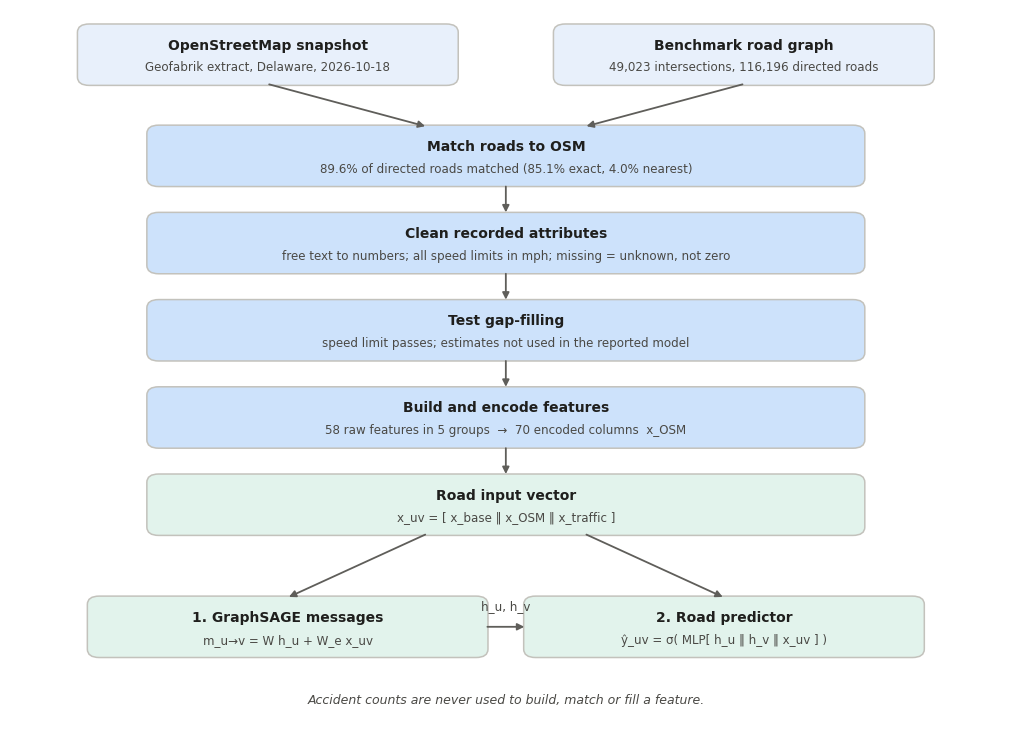

In [15]:
from src.osm.report import (
    load_osm_results, osm_comparison_table, permutation_table,
    plot_osm_comparison, plot_osm_pipeline,
)

fig = plot_osm_pipeline()
plt.show()

*Figure O1. The OSM feature pipeline for Delaware. The OSM snapshot and the benchmark road graph are matched road by road, and the recorded attributes are cleaned and encoded into the vector $x^{\mathrm{OSM}}$, which is appended to each road's input and used both in GraphSAGE's messages and in the road predictor. Accident counts are not used at any stage of feature construction.*

#### Integration into the Model

The OSM features are added to the baseline model without changing its architecture. For each directed road $(u, v)$ in month $t$, the 70 encoded OSM columns are appended to the road's existing input:

$$x_{uv,t} = \big[\, x^{\mathrm{base}}_{uv} \,\|\, x^{\mathrm{OSM}}_{uv} \,\|\, x^{\mathrm{traffic}}_{uv,t} \,\big],$$

where $x^{\mathrm{base}}_{uv}$ contains the benchmark's road-type indicators and length, $x^{\mathrm{traffic}}_{uv,t}$ the monthly traffic volume, and $\|$ denotes concatenation. In the benchmark's edge-aware GraphSAGE (Hamilton et al., 2017; Nippani et al., 2023), this vector is used in two places, as shown in Figure O1. First, it forms part of every message that an intersection receives from its neighbours:

$$\tilde h^{(\ell+1)}_v = \frac{1}{d_v + 1}\Big[\, W^{(\ell)} h^{(\ell)}_v + \sum_{u \in \mathcal{N}(v)} \big( W^{(\ell)} h^{(\ell)}_u + W^{(\ell)}_e\, x_{uv,t} \big) \Big], \qquad h^{(\ell+1)}_v = \mathrm{BN}\!\left( \frac{\tilde h^{(\ell+1)}_v}{\lVert \tilde h^{(\ell+1)}_v \rVert_2} \right).$$

Here $h^{(\ell)}_v$ is the representation of intersection $v$ after $\ell$ layers, $\mathcal{N}(v)$ its neighbours, $d_v$ its number of neighbours, $W^{(\ell)}$ and $W^{(\ell)}_e$ learned weight matrices, and BN batch normalisation; a ReLU activation is applied between the two layers, and biases are omitted. The initial representation $h^{(0)}_v$ contains the node features: coordinates, degree, betweenness, weather and, when used, Node2Vec embeddings. Second, the vector is passed directly to the predictor, which estimates the probability that road $(u, v)$ has at least one accident in month $t$:

$$\hat p_{uv,t} = \sigma\Big( \mathrm{MLP}\big[\, h^{(2)}_u \,\|\, h^{(2)}_v \,\|\, x_{uv,t} \,\big] \Big).$$

Each intersection's representation therefore reflects the OSM features of the roads around it, while the predictor also sees the features of the road being scored. The training procedure, loss function and checkpoint selection are identical to those of the baseline.

#### Experimental Design

To measure the effect of the OSM features, we compared four versions of the GraphSAGE classifier on Delaware, formed by including or omitting the OSM features and the Node2Vec embeddings. Including Node2Vec as a second factor tests whether the OSM features add information beyond what the network structure already provides. All four versions use the baseline's training protocol, data splits and evaluation metrics, and each was trained with three random seeds. The two versions without OSM features serve as controls. The control with Node2Vec was retrained through the same code as the OSM runs with the OSM columns omitted, and it reproduces the baseline result (AUROC 0.8743); the control without Node2Vec is the baseline run reported earlier. The four versions therefore differ only in their inputs.

To understand which features the trained models rely on, we also computed permutation importance (Fisher et al., 2019). For each feature group in turn, its values are randomly shuffled across roads in the test data while all other inputs are left unchanged, and the resulting drop in test AUROC is recorded. A large drop indicates that the model depends on that group. The shuffle was repeated three times for each of the three trained models, and the drops were averaged. Because the model is not retrained, this measures how much the fitted model relies on a group, not how much accuracy the group would add if introduced on its own.

#### Results

Table O5 and Figure O2 compare the four versions. Adding the OSM features improves the classifier in both settings. Without Node2Vec, test AUROC rises from 0.8461 to 0.8713, an increase of 0.0252; with Node2Vec, it rises from 0.8743 to 0.8772, an increase of 0.0029. All three seeds improve in both settings, and each increase is larger than the variation between seeds of the corresponding control (standard deviations of 0.0037 and 0.0003).

The improvement also appears in the metrics that matter when roads are prioritised for inspection. Without Node2Vec, average precision rises from 0.213 to 0.255, and precision among the 1% of roads ranked riskiest each month rises from 0.392 to 0.445: of every hundred roads the model flags, about five more go on to have an accident. With Node2Vec, the same metrics improve by smaller margins.

In [16]:
osm_results = load_osm_results(PROJECT_DIR)
display(osm_comparison_table(osm_results).style.format({'Change': '{:+.4f}'}).set_caption(
    'Table O5. Test performance of the four versions of the Delaware GraphSAGE classifier, as mean ± standard deviation '
    'over three seeds. "Seeds improved" counts the seeds for which the version with OSM features outperforms the control '
    'trained with the same seed.'))

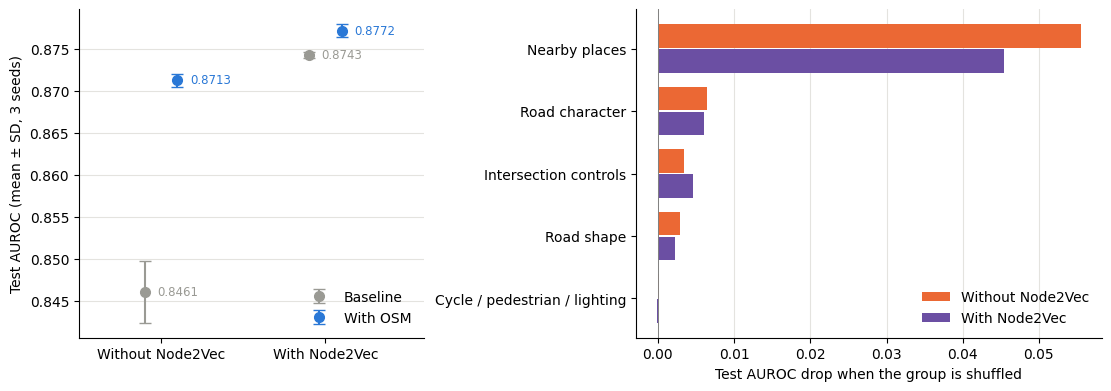

In [17]:
fig = plot_osm_comparison(osm_results)
plt.show()

*Figure O2. Left: test AUROC of the four versions, as mean ± standard deviation over three seeds; the vertical axis does not start at zero. Right: drop in test AUROC when each OSM feature group is shuffled across roads; a larger drop indicates greater reliance on that group.*

#### Discussion

The permutation results show which features produce the improvement. Shuffling the nearby-places group reduces test AUROC by 0.0555 without Node2Vec and by 0.0454 with it, more than half of the reduction caused by shuffling all OSM features together (0.0908 and 0.0791). The road-character, intersection-control and road-shape groups each reduce it by less than 0.007, and the cycle, pedestrian and lighting group has no measurable effect. This ordering follows coverage: nearby-place features are available for every road, whereas the speed limit, number of lanes and lighting are recorded for between 0.6% and 14% of roads, which leaves the model little to learn from. It is also consistent with the association analysis, in which busy surroundings showed the strongest and most stable relationship with accident rates. Nearby-place counts probably act in part as a proxy for traffic exposure, which the benchmark otherwise lacks; the measured traffic volume has no effect when shuffled, because it is recorded for at most 1.1% of roads in any year and is therefore almost constant. Because permutation measures reliance rather than added value, correlated groups may substitute for one another, and these figures should not be read as the gain from each group alone.

The OSM features help far more without Node2Vec (an increase of 0.0252) than with it (0.0029). This suggests that the two inputs provide largely the same information, so that once one is present, the other adds little.

Two results support this. First, the gains do not add up: Node2Vec alone raises AUROC by 0.0282 and the OSM features alone by 0.0252, but both together raise it by only 0.0311, far less than the 0.0534 expected if they were independent. Second, when Node2Vec is present, the model depends less on the OSM features: shuffling them reduces AUROC by 0.0791 rather than 0.0908.

To find out what the shared information is, we tested whether a road's Node2Vec embedding can predict how busy its surroundings are, measured by the number of points of interest within 1 km (`notebooks/osm_node2vec_density_check.ipynb`). The result depends on where the test roads lie. For roads in parts of Delaware not used to fit the prediction, the embedding predicts almost nothing (R² of at most 0.07); for roads in areas that were used, it predicts well (R² of 0.67 to 0.70). Node2Vec therefore does not capture a general property such as "busy area"; it captures *where* a road is, which is only useful for places the model has already seen.

This explains the overlap, because in our evaluation the model always sees the same roads: it is trained on 2009–2012 and tested on 2018–2022 on the same network, and accidents tend to recur on the same roads. Recognising a road is therefore enough to predict much of its risk. Node2Vec lets the model recognise roads by their position in the network, and the OSM features plausibly do the same through each location's distinctive combination of nearby places. Because both serve this purpose, combining them brings little extra benefit. Diminishing returns at higher accuracy may also contribute, but they cannot be the main reason, since the OSM features alone raise AUROC almost as much as Node2Vec does.

The improvement is also consistent over time and across road types. With Node2Vec, monthly AUROC is higher with the OSM features in all 57 test months, with a mean increase of 0.0029 and a bootstrap interval over months of 0.0026 to 0.0031; this interval treats months as independent and is therefore likely to be somewhat too narrow. The gain is larger on motorways (0.0142 across 706 roads) than on residential roads (0.0029 across 44,294 roads), which is consistent with the more complete mapping of major roads, although the two road types also differ in accident frequency. These two analyses require the saved predictions of each model and are reported from `notebooks/osm_baseline_comparison.ipynb` (Sections 10–11).

Finally, the OSM features narrow the gap between models but do not change their order. With OSM features and Node2Vec, GraphSAGE reaches an AUROC of 0.8772, slightly below the 0.8780 achieved by the MLP with Node2Vec in the baseline comparison. We did not add OSM features to the MLP, so it remains open whether they would benefit a model without message passing to the same extent.

#### Limitations and Future Work

The most important limitation concerns timing. The OSM snapshot dates from 2026, whereas the accident records cover 2009 to 2022. Roads built and safety measures introduced after an accident, possibly in response to it, are therefore visible to the model, so the reported gains are best interpreted as an upper bound on what a forecast made with the map available at the time would achieve. As noted earlier, a single snapshot was used because processing one extract per accident year exceeded the resources of this project. Geofabrik's archive provides dated Delaware extracts from January 2014 onwards, so matching each test year to the map of that year is a feasible next step, although extracts for the training years 2009–2012 are not available from this source.

Second, the Discussion suggests that much of the benefit of both Node2Vec and the OSM features comes from recognising roads whose risk has already been observed. The present evaluation, which tests the same roads in later years, rewards this. It does not show whether the OSM features would help on roads or regions the model has never seen, which is the setting that matters when transferring the model to another network such as Singapore's. A spatially held-out evaluation would test this directly; because the OSM features, unlike Node2Vec, describe general properties of a location, they may transfer better.

Third, the most interpretable attributes are sparse and selectively mapped. Speed limits, lane counts and surfaces are recorded mainly on major roads, so conclusions about them describe those roads rather than the network as a whole. Richer attribute sources, such as state road inventories, could fill these gaps.

Finally, the scope of the experiment is narrow: a single state, a single model and a single task, with three seeds and one Node2Vec embedding, so the reported standard deviations do not capture variation from the embedding or from geography. The pipeline itself is not specific to Delaware: extraction, matching and feature construction take the state as a parameter and apply to any Geofabrik extract. It was run only for Delaware because Maryland, with 580,526 directed roads, five times as many, exceeded the memory and compute available to this project. The static OSM features were also standardised over the whole network, including roads observed only in the test period; no accident information is involved, but the scaling is not strictly limited to training data. Retraining the model with each feature group removed would measure each group's own contribution, which permutation importance cannot.

### Accident History

> *Placeholder for the accident-history owner, using the same Motivation → Method → Results → Analysis structure. Existing material: "Past-only accident-history representation" (Methodology) and "Historical persistence of accident incidence" (Results), plus the history-enabled runs in `results/history_v1/`.*

## Limitations

Predictive results are restricted to Delaware, and models use one fixed structural embedding across three model seeds. The seed standard deviations exclude uncertainty from embedding generation, geographic sampling and temporal dependence. The results consequently support conclusions about these experimental settings rather than geographic transfer or general architectural superiority.

Missing traffic exposure (AADT is observed on 3.16% of Delaware's physical roads) constrains the interpretation of every feature association. Limitations specific to the OpenStreetMap features are discussed with those results.

Accident counts and descriptive rate ratios do not establish exposure-adjusted or causal road safety effects. Historical persistence is evaluated descriptively, permutation scores measure fitted-model reliance, and the exploratory bootstrap does not account for serial dependence. Classification calibration is not assessed. These distinctions limit the use of the results for intervention selection or probability-based operational decisions.


## Conclusion

This study evaluates structural embeddings, learned message passing and OSM road context for monthly accident prediction. Node2Vec improves both MLP and GraphSAGE baselines, while the relative value of message passing depends on the task: the MLP leads classification and GraphSAGE leads count regression when embeddings are included. OSM improves GraphSAGE classification under both embedding settings, with a substantially larger increment without Node2Vec. Nearby-place attributes have the greatest measured permutation sensitivity, and prior own-road counts exhibit strong training-period persistence.

These findings support evaluating graph encoders against strong non-message-passing controls and auditing feature availability alongside predictive gains. Retrospective map timing and incomplete exposure information constrain interpretation. The evidence establishes conditional predictive improvements in Delaware and a descriptive basis for accident-history modelling, rather than causal effects or validated geographic transfer.


## References

Ahmad, N., Wali, B., Khattak, A. J., & Dumbaugh, E. (2021). Built environment, driving errors and violations, and crashes in naturalistic driving environment. Accident Analysis & Prevention, 157, 106158.

Boeing, G. (2025). Modeling and analyzing urban networks and amenities with OSMnx. Geographical Analysis.

Bresson, X., & Laurent, T. (2017). Residual gated graph convnets. arXiv Preprint arXiv:1711.07553.

Castillo, R. C., Staguhn, E. D., & Weston-Farber, E. (2020). The effect of state-level stay-at-home orders on COVID-19 infection rates. American Journal of Infection Control, 48(8), 958–960.

Defferrard, M., Bresson, X., & Vandergheynst, P. (2016). Convolutional neural networks on graphs with fast localized spectral filtering. Advances in Neural Information Processing Systems, 29.

Dwivedi, V. P., & Bresson, X. (2020). A generalization of transformer networks to graphs. arXiv Preprint arXiv:2012.09699.

Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. Journal of Machine Learning Research, 20(177), 1–81.

Geofabrik GmbH, & OpenStreetMap contributors. (2026). Delaware OpenStreetMap extract, 18 October 2026 (delaware-261018.osm.pbf) [Data set]. Open Database Licence 1.0. https://download.geofabrik.de/north-america/us/delaware.html

Goodchild, M. F., & Hunter, G. J. (1997). A simple positional accuracy measure for linear features. International Journal of Geographical Information Science, 11(3), 299–306. https://doi.org/10.1080/136588197242419

Grover, A., & Leskovec, J. (2016). node2vec: Scalable feature learning for networks. Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 855–864.

Guerra, A., Gadhiya, V., & Srisurin, P. (2022). Crash prediction on road segments using machine learning methods. ASEAN Engineering Journal, 12(3), 27–37.

Haklay, M. (2010). How good is volunteered geographical information? A comparative study of OpenStreetMap and Ordnance Survey datasets. Environment and Planning B: Planning and Design, 37(4), 682–703. https://doi.org/10.1068/b35097

Hamilton, W., Ying, Z., & Leskovec, J. (2017). Inductive representation learning on large graphs. Advances in Neural Information Processing Systems, 30.

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. Neural Computation, 9(8), 1735–1780.

Huang, B., & Hooi, B. (2022). Traffic accident prediction using graph neural networks: New datasets and the TRAVEL model. Traffic, 27(29), 31.

Kashifi, M. T., Al-Turki, M., & Sharify, A. W. (2023). Deep hybrid learning framework for spatiotemporal crash prediction using big traffic data. International Journal of Transportation Science and Technology, 12(3), 793–808.

Kipf, T. N., & Welling, M. (2016). Semi-supervised classification with graph convolutional networks. arXiv Preprint arXiv:1609.02907.

Ma, Z., Zhang, H., Steven, I., Chien, J., Wang, J., & Dong, C. (2017). Predicting expressway crash frequency using a random effect negative binomial model: A case study in China. Accident Analysis & Prevention, 98, 214–222.

MacKinnon, J. G., & White, H. (1985). Some heteroskedasticity-consistent covariance matrix estimators with improved finite sample properties. Journal of Econometrics, 29(3), 305–325.

Mikolov, T., Chen, K., Corrado, G., & Dean, J. (2013). Efficient estimation of word representations in vector space. arXiv Preprint arXiv:1301.3781.

Nippani, A., Li, D., Ju, H., Koutsopoulos, H., & Zhang, H. (2023). Graph Neural Networks for Road Safety Modeling: Datasets and Evaluations for Accident Analysis. Advances in Neural Information Processing Systems Datasets and Benchmarks Track, 36.

OpenStreetMap contributors. (n.d.). Key:maxspeed. OpenStreetMap Wiki. https://wiki.openstreetmap.org/wiki/Key:maxspeed

Perozzi, B., Al-Rfou, R., & Skiena, S. (2014). Deepwalk: Online learning of social representations. Proceedings of the 20th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining, 701–710.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). Attention is all you need. Advances in Neural Information Processing Systems, 30.

Wijnen, W., & Stipdonk, H. (2016). Social costs of road crashes: An international analysis. Accident Analysis & Prevention, 94, 97–106.

## Appendix A. OpenStreetMap Feature Catalogue

| Group | Feature | Definition | OSM source | Type | Encoding | Roads with a value |
|---|---|---|---|---|---|---|
| Road character | Speed limit | Posted limit of the matched road (highest if several) | `maxspeed` | mph | standardised, indicator | 13.9% |
| Road character | Number of lanes | Lane count of the matched road (highest if several) | `lanes` | count | limited to 1–8, standardised, indicator | 12.6% |
| Road character | Surface | asphalt, concrete, gravel, paved, unpaved, mixed, other | `surface` | category | one-hot, indicator | 17.3% |
| Road character | Bridge | Road is mapped as a bridge | `bridge` | 0/1 | as is | 89.6% |
| Road character | Tunnel | Road is mapped as a tunnel | `tunnel` | 0/1 | as is | 89.6% |
| Intersection control | Control at road ends (8 features) | Signal, stop sign, give-way sign or crossing at the start or end node | `highway=traffic_signals`, `stop`, `give_way`, `crossing`; `crossing=*` | 0/1 | as is (give-way features dropped: no variation) | 89.6% |
| Intersection control | Roundabout | Road is part of a roundabout | `junction=roundabout`, `circular` | 0/1 | as is | 89.6% |
| Intersection control | Control between junctions (5 features) | Signals, stop signs, give-way signs, crossings and traffic-calming devices within 15 m of the road, removed by simplification | as above; `traffic_calming=*` | count | log(1 + x), standardised | 89.6% |
| Cycle, pedestrian, lighting | Cycle lane | A cycle lane is mapped on either side | `cycleway`, `cycleway:left/right/both` | yes / no / unknown | value and indicator | 2.4% |
| Cycle, pedestrian, lighting | Sidewalk | A sidewalk is mapped | `sidewalk` | yes / no / unknown | value and indicator | 1.5% |
| Cycle, pedestrian, lighting | Street lighting | The road is mapped as lit | `lit` | yes / no / unknown | value and indicator | 0.6% |
| Nearby places | Counts within 100, 250, 500 and 1,000 m (28 features) | Number of schools, bus stops, food outlets, bars, parking areas, crossings and signals around the road's midpoint | `amenity=school`, `restaurant`, `fast_food`, `bar`, `pub`, `parking`; `highway=bus_stop`; control points | count | log(1 + x), standardised | 100% |
| Nearby places | Distance to nearest (7 features) | Distance from the road's midpoint to the nearest point of each kind | as above | metres | log(1 + x), standardised | 100% |
| Road shape | Curvature ratio | Road length divided by the straight-line distance between its ends | benchmark geometry | ratio | limited to 1–5, standardised, indicator | 99.4% |
| Matching | Unmatched indicator | Road has no OSM match | matching step | 0/1 | as is | 100% |

*Table A1. Complete catalogue of the 58 OpenStreetMap features (70 encoded columns) for Delaware. "OSM source" gives the OpenStreetMap key from which each feature is derived, so that the extraction can be reproduced. Source: `notebooks/osm_features_and_eda.ipynb`, Stages 6, 7.1 and 13.*

Two construction details are recorded here for completeness. First, standard simplification of the OSM network into a graph removes nodes that are not junctions, together with any control point mapped on them; in Delaware this removed 39% of traffic signals, 84% of stop signs and more than 99% of crossings and traffic-calming devices. These points were recovered from the raw extract and assigned to the nearest road within 15 m, giving the "between junctions" counts. Second, to limit the influence of likely mapping errors, lane counts were restricted to 1–8 and the curvature ratio to 1–5; surfaces recorded on fewer than 50 roads were grouped as "other", standardised values were limited to ±10 standard deviations, and missing-value indicators were added for features missing on more than 0.5% of matched roads. The full construction, with diagnostics, is in `notebooks/osm_features_and_eda.ipynb` (Stages 6–7 and 13).